In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 68.3 MB/s  0:00:01


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

In [3]:
df = pd.read_csv("Adult Census Income.csv")

In [4]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [5]:
df.shape

(32561, 15)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [7]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [8]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='object')

In [9]:
df.duplicated().sum()

np.int64(24)

In [10]:
df = df.drop_duplicates()

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df = df.replace("?", np.nan)

In [13]:
df.isnull().sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,1843
relationship,0
race,0
sex,0


In [14]:
df["workclass"] = df["workclass"].fillna(df["workclass"].mode()[0])
df["occupation"] = df["occupation"].fillna(df["occupation"].mode()[0])
df["native.country"] = df["native.country"].fillna(df["native.country"].mode()[0])

In [15]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,0
relationship,0
race,0
sex,0


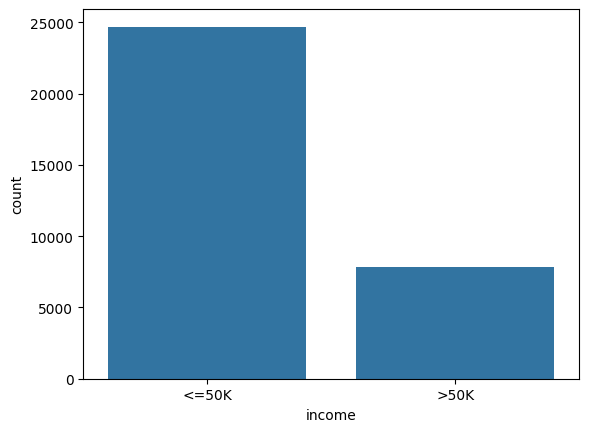

In [16]:
sns.countplot(x="income", data=df)
plt.show()

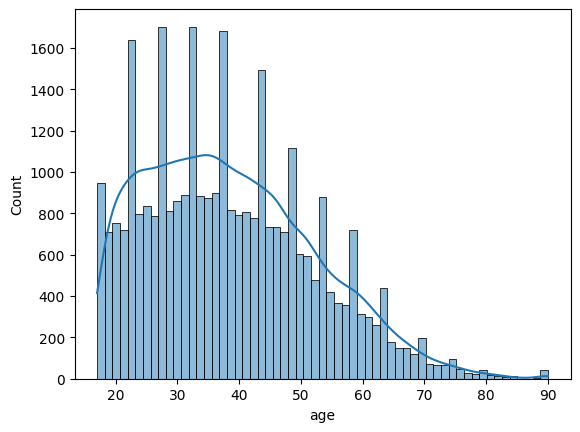

In [17]:
sns.histplot(df["age"], kde=True)
plt.show()

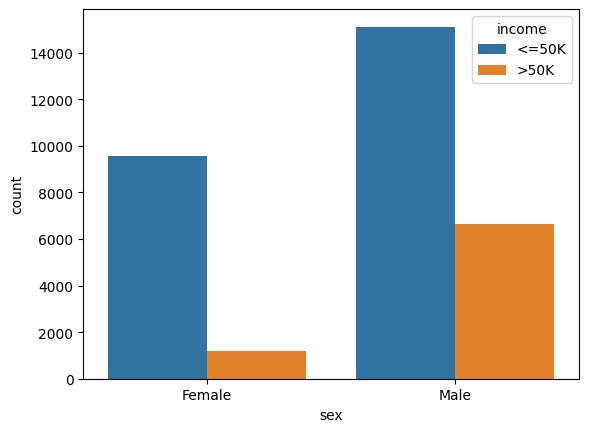

In [18]:
sns.countplot(x="sex", hue="income", data=df)
plt.show()

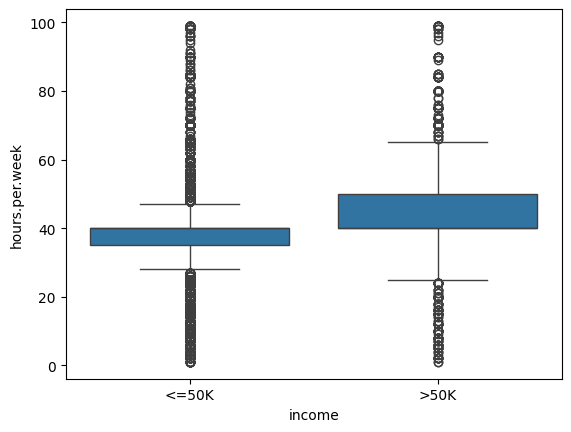

In [19]:
sns.boxplot(x="income", y="hours.per.week", data=df)
plt.show()

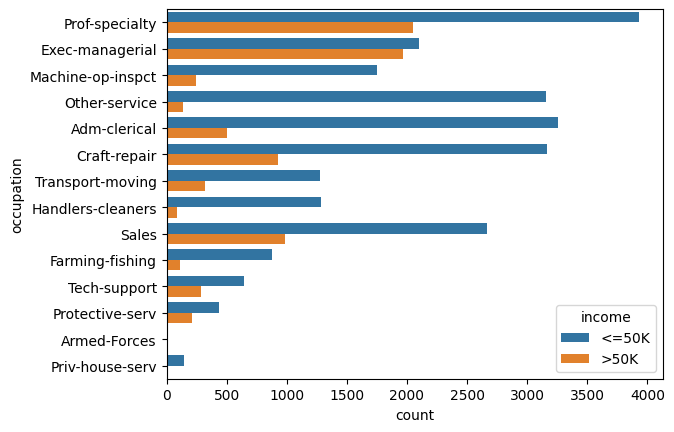

In [20]:
sns.countplot(y="occupation", hue="income", data=df)
plt.show()

In [21]:
df["income"] = df["income"].map({"<=50K": 0, ">50K": 1})
df["sex"] = df["sex"].map({"Female": 0, "Male": 1})

In [22]:
df = df.drop(columns=["education", "fnlwgt"])

In [23]:
df = pd.get_dummies(df, columns=["workclass", "marital.status", "occupation", "relationship", "race"], drop_first=True, dtype=int)

In [24]:
X = df.drop(columns="income")
y = df["income"]

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [26]:
country_mean = y_train.groupby(X_train["native.country"]).mean()
X_train["native.country"] = X_train["native.country"].map(country_mean)
X_test["native.country"] = X_test["native.country"].map(country_mean).fillna(y_train.mean())

In [27]:
X_train["capital.gain"] = np.log1p(X_train["capital.gain"])
X_test["capital.gain"] = np.log1p(X_test["capital.gain"])
X_train["capital.loss"] = np.log1p(X_train["capital.loss"])
X_test["capital.loss"] = np.log1p(X_test["capital.loss"])

In [30]:
cols = ["age", "education.num", "capital.gain", "capital.loss", "hours.per.week", "native.country"]
scaler = StandardScaler()
X_train[cols] = scaler.fit_transform(X_train[cols])
X_test[cols] = scaler.transform(X_test[cols])

In [31]:
y_train.value_counts()
results = []
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("X_train_smote = ", X_train_smote.shape, " y_train_smote = ", y_train_smote.shape)
y_train_smote.value_counts()
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("X_train_rus = ", X_train_rus.shape, " y_train_rus = ", y_train_rus.shape)

y_train_rus.value_counts()


X_train_smote =  (39420, 42)  y_train_smote =  (39420,)
X_train_rus =  (12638, 42)  y_train_rus =  (12638,)


,count
income,
0,6319
1,6319


In [32]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Model': "Logistic Regression",
    'Method': "Normal Data",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [33]:
# Logistic Regression - SMOTE Over Sampling
model = LogisticRegression(max_iter=1000)
model.fit(X_train_smote, y_train_smote)
y_pred = model.predict(X_test)

results.append({
    'Model': "Logistic Regression",
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [34]:
# Logistic Regression - Random Under Sampling
model = LogisticRegression(max_iter=1000)
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test)

results.append({
    'Model': "Logistic Regression",
    'Method': "Random Under Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [35]:
# Logistic Regression - Class Weight Balanced
model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Model': "Logistic Regression",
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [36]:
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Model': "KNN",
    'Method': "Normal Data",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [37]:
# KNN - SMOTE Over Sampling
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X_train_smote, y_train_smote)
y_pred = model.predict(X_test)

results.append({
    'Model': "KNN",
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [38]:
# KNN - Random Under Sampling
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test)

results.append({
    'Model': "KNN",
    'Method': "Random Under Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [39]:
model = GaussianNB(var_smoothing=0.1)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Model': "Naive Bayes",
    'Method': "Normal Data",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [40]:
# Naive Bayes - SMOTE Over Sampling
model = GaussianNB(var_smoothing=0.1)
model.fit(X_train_smote, y_train_smote)
y_pred = model.predict(X_test)

results.append({
    'Model': "Naive Bayes",
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [41]:
# Naive Bayes - Random Under Sampling
model = GaussianNB(var_smoothing=0.1)
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test)

results.append({
    'Model': "Naive Bayes",
    'Method': "Random Under Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [42]:
results_df = pd.DataFrame(results).set_index(['Model', 'Method'])
results_df.round(3)

Accuracy  Precision  Recall  \
Model               Method                                               
Logistic Regression Normal Data               0.843      0.689   0.599   
                    SMOTE Over Sampling       0.800      0.548   0.816   
                    Random Under Sampling     0.798      0.544   0.838   
                    Class Weight Balanced     0.798      0.544   0.843   
KNN                 Normal Data               0.848      0.677   0.664   
                    SMOTE Over Sampling       0.783      0.522   0.859   
                    Random Under Sampling     0.785      0.525   0.870   
Naive Bayes         Normal Data               0.774      0.510   0.843   
                    SMOTE Over Sampling       0.727      0.457   0.905   
                    Random Under Sampling     0.738      0.469   0.893   

                                           F1-Score  
Model               Method                           
Logistic Regression Normal Data               0.641  
                    SMOTE Over Sampling       0.656  
                    Random Under Sampling     0.660  
                    Class Weight Balanced     0.661  
KNN                 Normal Data               0.670  
                    SMOTE Over Sampling       0.649  
                    Random Under Sampling     0.654  
Naive Bayes         Normal Data               0.636  
                    SMOTE Over Sampling       0.607  
                    Random Under Sampling     0.615

In [43]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[4577  411]
 [ 609  911]]


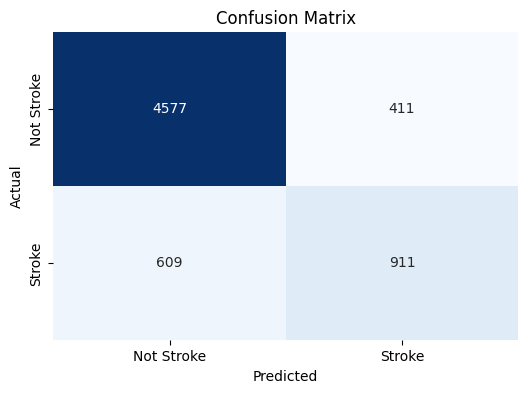


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.92      0.90      4988
      Stroke       0.69      0.60      0.64      1520

    accuracy                           0.84      6508
   macro avg       0.79      0.76      0.77      6508
weighted avg       0.84      0.84      0.84      6508

ROC-AUC: 0.894646625585616


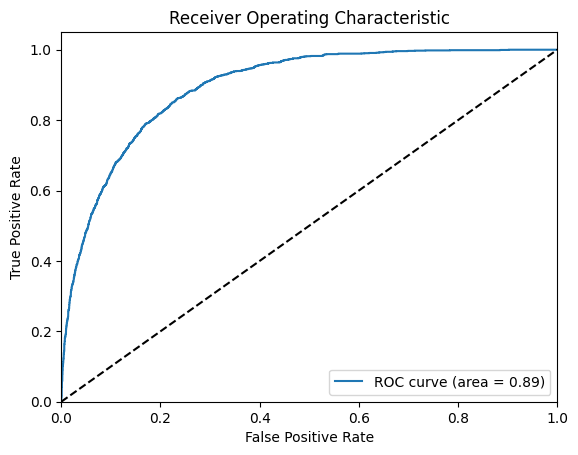

PR AUC: 0.7159874957892417


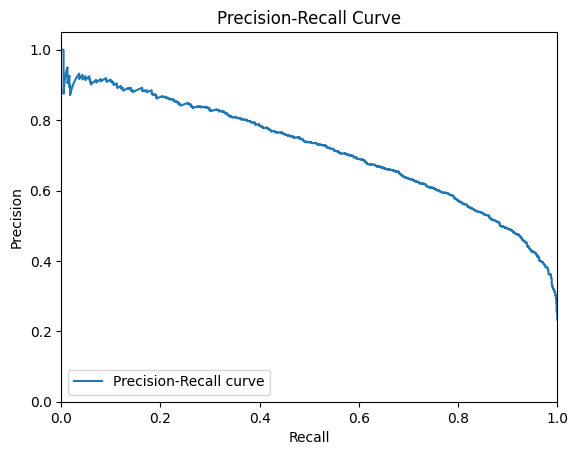

  8%|▊         | 1/13 [00:01<00:17,  1.47s/it]


Confusion Matrix:
 [[4468  520]
 [ 536  984]]


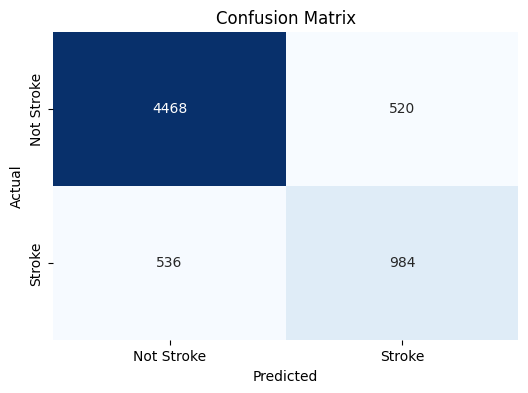


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.90      0.89      4988
      Stroke       0.65      0.65      0.65      1520

    accuracy                           0.84      6508
   macro avg       0.77      0.77      0.77      6508
weighted avg       0.84      0.84      0.84      6508

ROC-AUC: 0.864726264086439


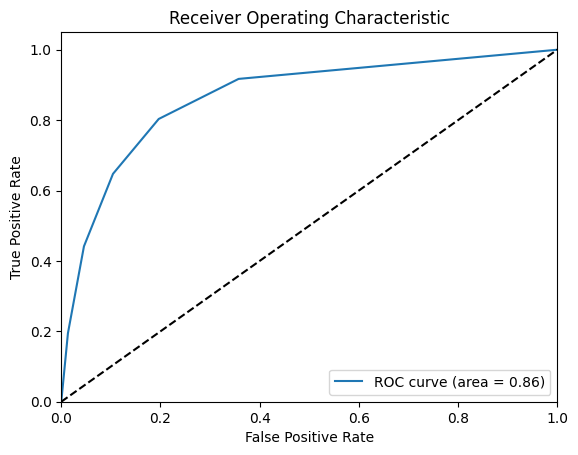

PR AUC: 0.6334572278775732


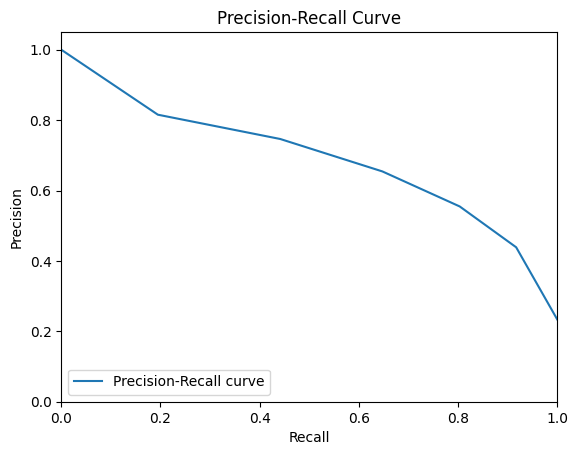

 15%|█▌        | 2/13 [00:09<00:56,  5.17s/it]


Confusion Matrix:
 [[4665  323]
 [ 605  915]]


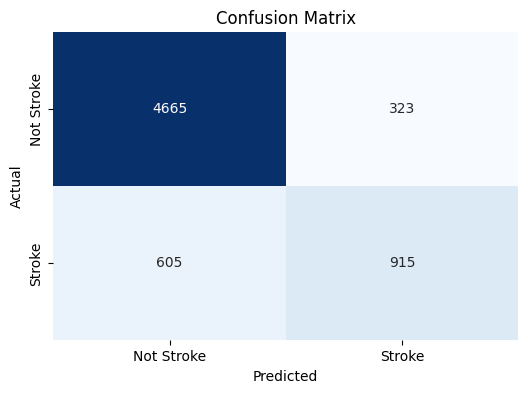


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.94      0.91      4988
      Stroke       0.74      0.60      0.66      1520

    accuracy                           0.86      6508
   macro avg       0.81      0.77      0.79      6508
weighted avg       0.85      0.86      0.85      6508

ROC-AUC: 0.8928685423964884


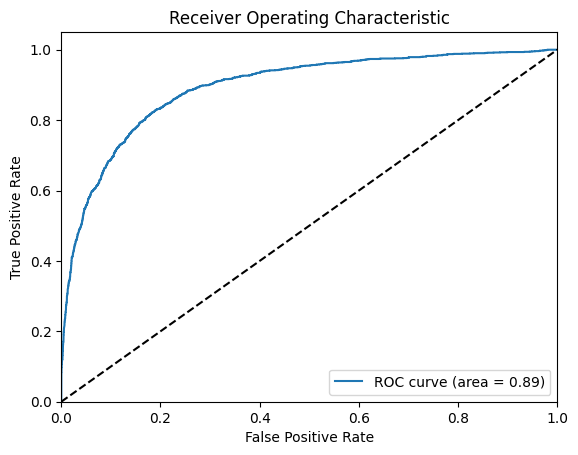

PR AUC: 0.7556022179397159


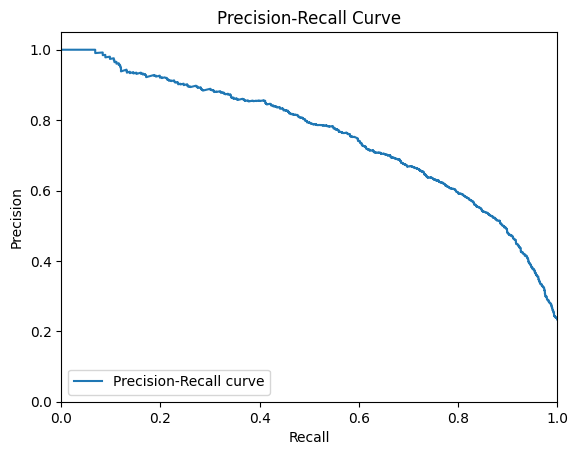

 23%|██▎       | 3/13 [02:36<11:42, 70.21s/it]


Confusion Matrix:
 [[4376  612]
 [ 588  932]]


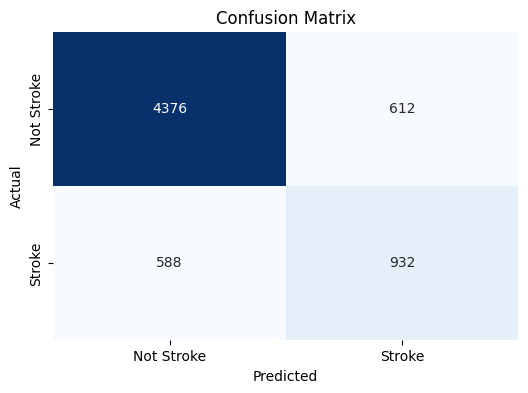


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.88      0.88      4988
      Stroke       0.60      0.61      0.61      1520

    accuracy                           0.82      6508
   macro avg       0.74      0.75      0.74      6508
weighted avg       0.82      0.82      0.82      6508

ROC-AUC: 0.7675582582408307


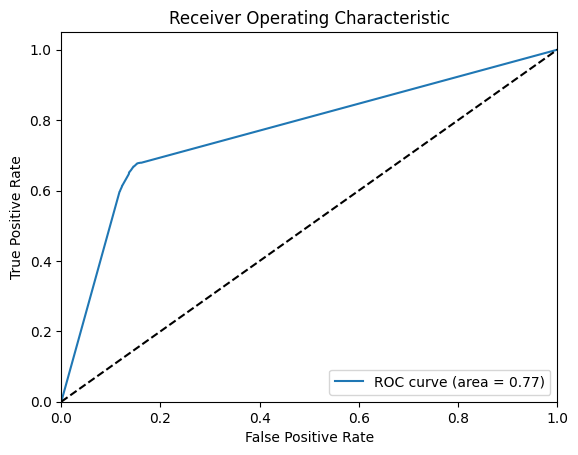

PR AUC: 0.4860502740440182


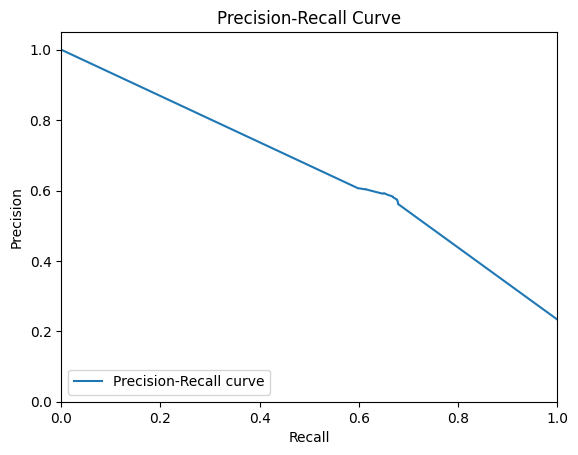

 31%|███       | 4/13 [02:37<06:25, 42.83s/it]


Confusion Matrix:
 [[1992 2996]
 [  61 1459]]


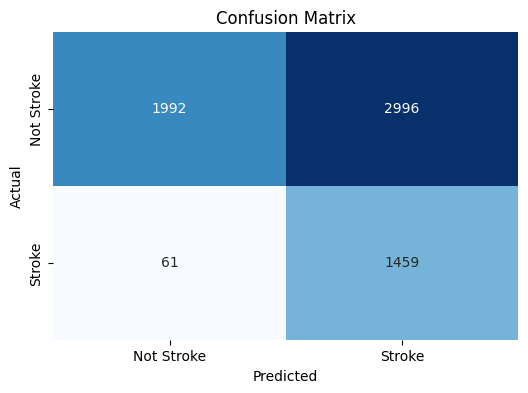


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.97      0.40      0.57      4988
      Stroke       0.33      0.96      0.49      1520

    accuracy                           0.53      6508
   macro avg       0.65      0.68      0.53      6508
weighted avg       0.82      0.53      0.55      6508

ROC-AUC: 0.8314986889587641


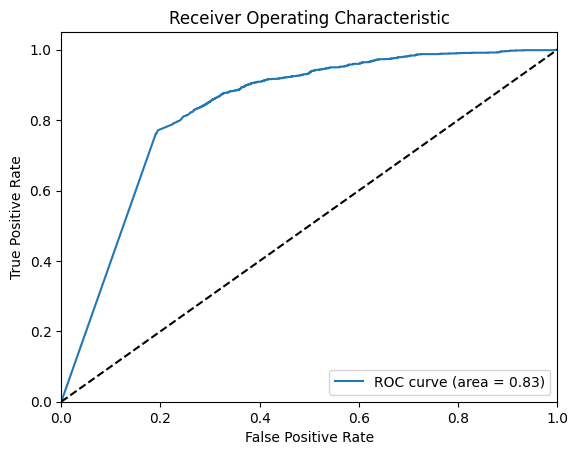

PR AUC: 0.5188894251480258


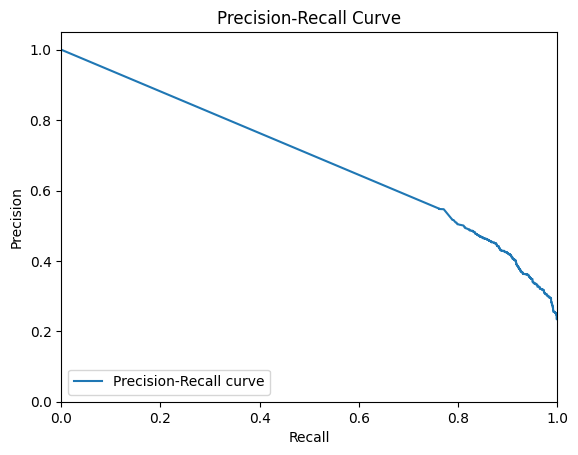

 38%|███▊      | 5/13 [02:38<03:40, 27.61s/it]


Confusion Matrix:
 [[4566  422]
 [ 553  967]]


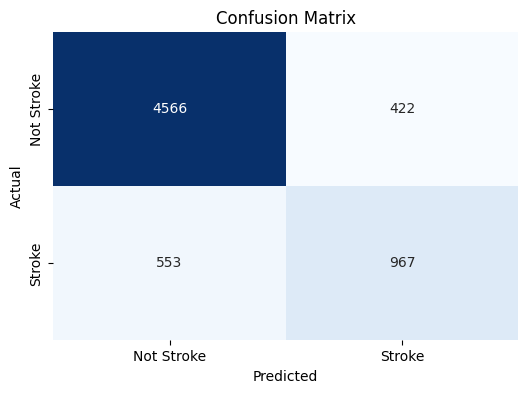


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.92      0.90      4988
      Stroke       0.70      0.64      0.66      1520

    accuracy                           0.85      6508
   macro avg       0.79      0.78      0.78      6508
weighted avg       0.85      0.85      0.85      6508

ROC-AUC: 0.8981125094964758


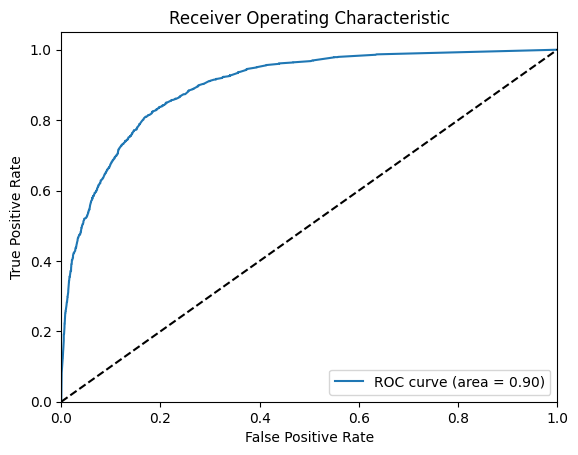

PR AUC: 0.7472513892956618


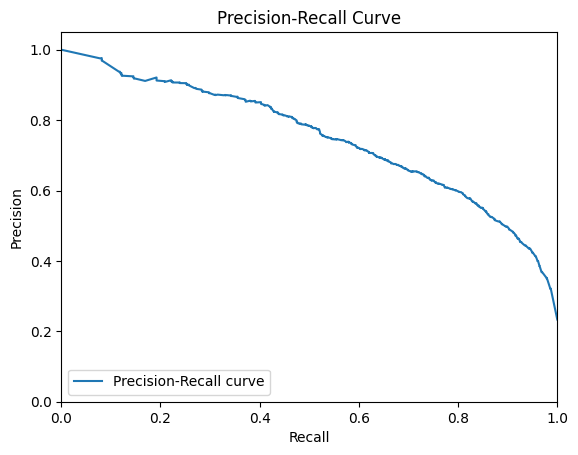

 46%|████▌     | 6/13 [02:42<02:17, 19.60s/it]


Confusion Matrix:
 [[4519  469]
 [ 570  950]]


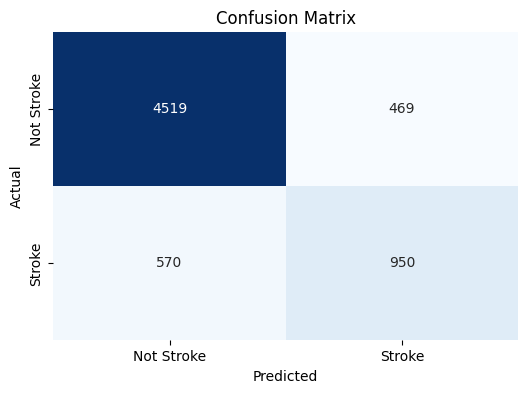


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.91      0.90      4988
      Stroke       0.67      0.62      0.65      1520

    accuracy                           0.84      6508
   macro avg       0.78      0.77      0.77      6508
weighted avg       0.84      0.84      0.84      6508

ROC-AUC: 0.8621198771789135


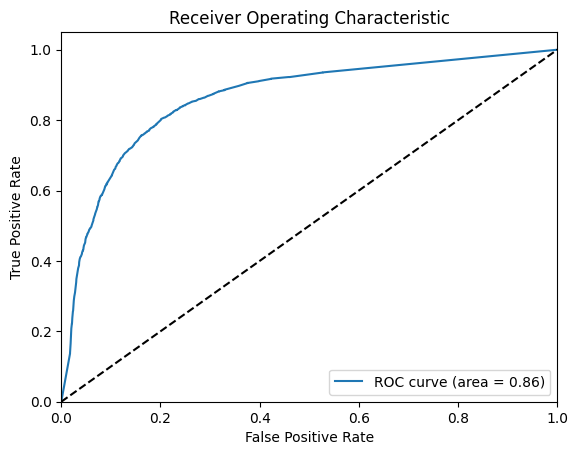

PR AUC: 0.6429411042541822


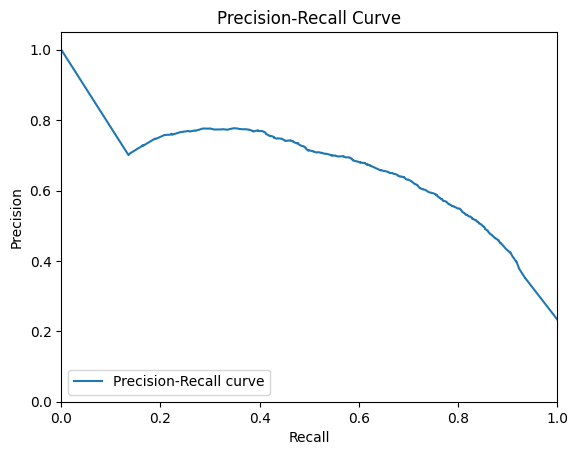

 54%|█████▍    | 7/13 [02:46<01:27, 14.64s/it]


Confusion Matrix:
 [[4722  266]
 [ 684  836]]


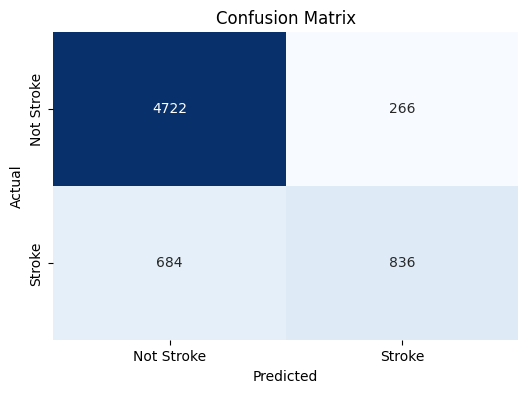


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.95      0.91      4988
      Stroke       0.76      0.55      0.64      1520

    accuracy                           0.85      6508
   macro avg       0.82      0.75      0.77      6508
weighted avg       0.85      0.85      0.85      6508

ROC-AUC: 0.8995339472629047


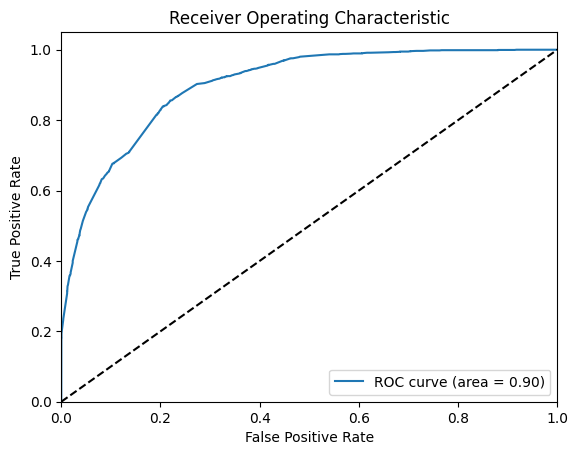

PR AUC: 0.7509976322710934


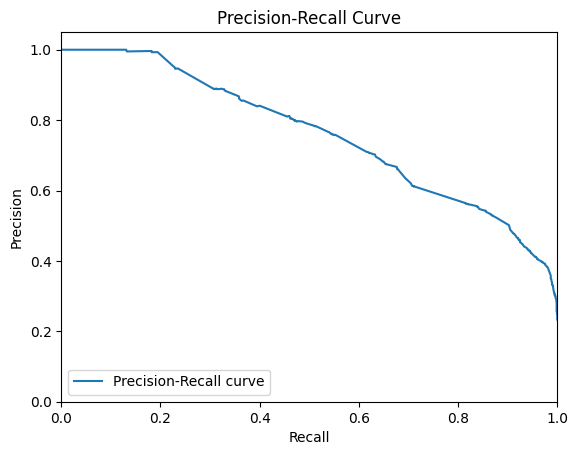

 62%|██████▏   | 8/13 [02:48<00:52, 10.42s/it]


Confusion Matrix:
 [[4715  273]
 [ 612  908]]


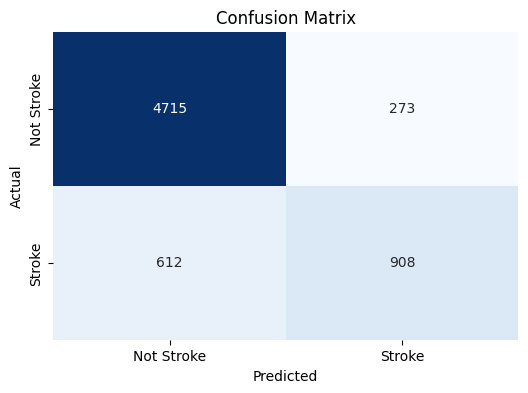


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.95      0.91      4988
      Stroke       0.77      0.60      0.67      1520

    accuracy                           0.86      6508
   macro avg       0.83      0.77      0.79      6508
weighted avg       0.86      0.86      0.86      6508

ROC-AUC: 0.920314148693707


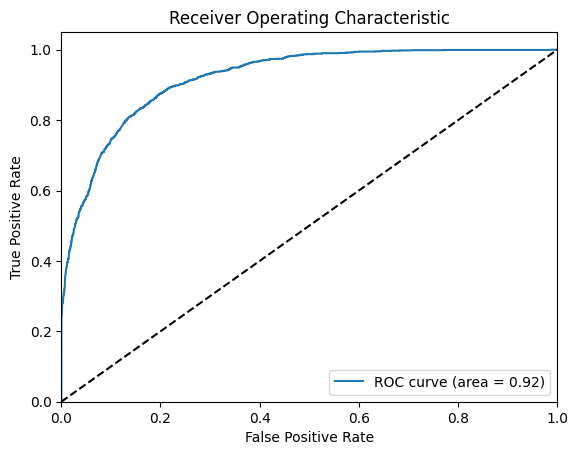

PR AUC: 0.8070029443113818


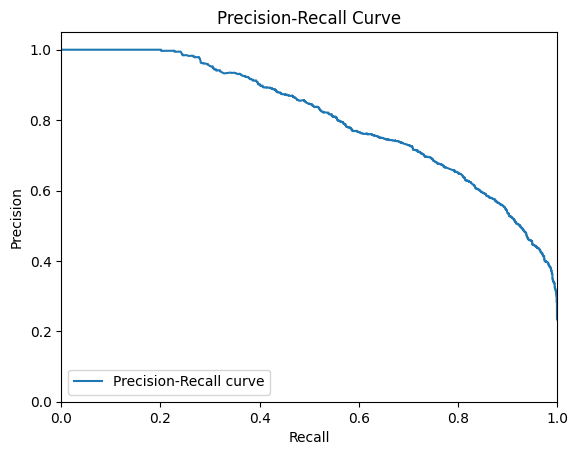

 69%|██████▉   | 9/13 [02:52<00:33,  8.46s/it]


Confusion Matrix:
 [[4662  326]
 [ 502 1018]]


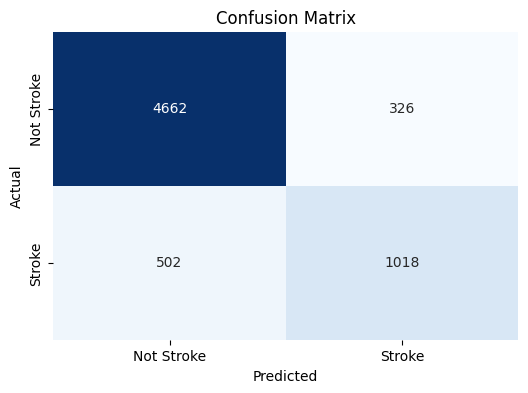


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.90      0.93      0.92      4988
      Stroke       0.76      0.67      0.71      1520

    accuracy                           0.87      6508
   macro avg       0.83      0.80      0.81      6508
weighted avg       0.87      0.87      0.87      6508

ROC-AUC: 0.9256511680665176


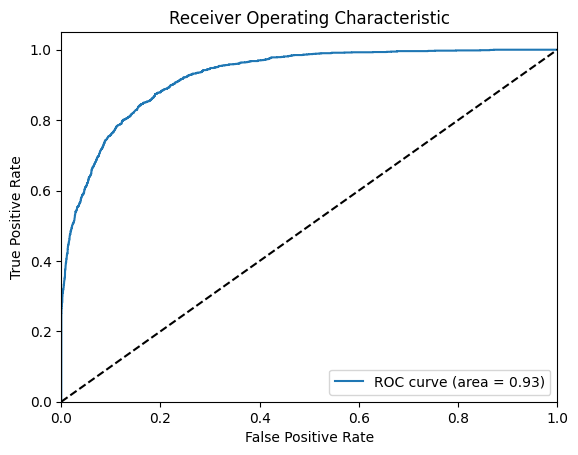

PR AUC: 0.8213953087679944


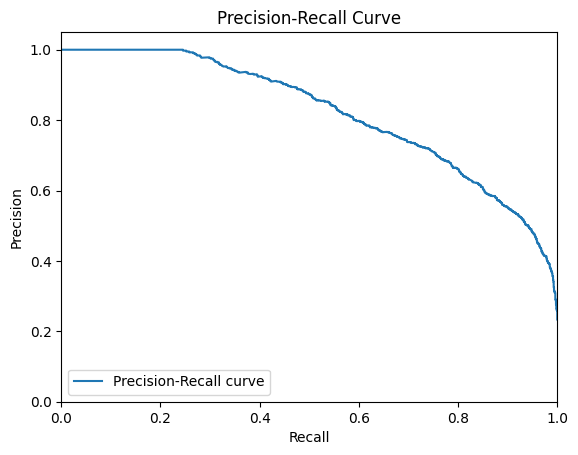

 77%|███████▋  | 10/13 [02:54<00:19,  6.50s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:00:29] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4661  327]
 [ 503 1017]]


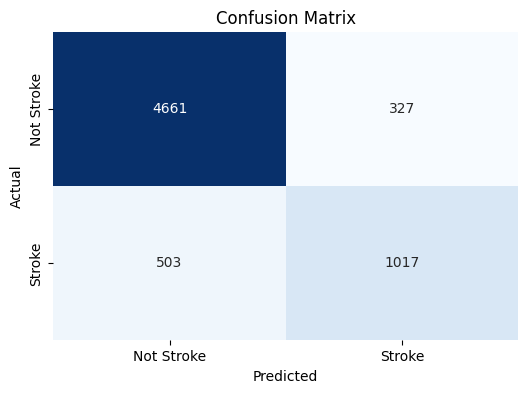


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.90      0.93      0.92      4988
      Stroke       0.76      0.67      0.71      1520

    accuracy                           0.87      6508
   macro avg       0.83      0.80      0.81      6508
weighted avg       0.87      0.87      0.87      6508

ROC-AUC: 0.9247770966108133


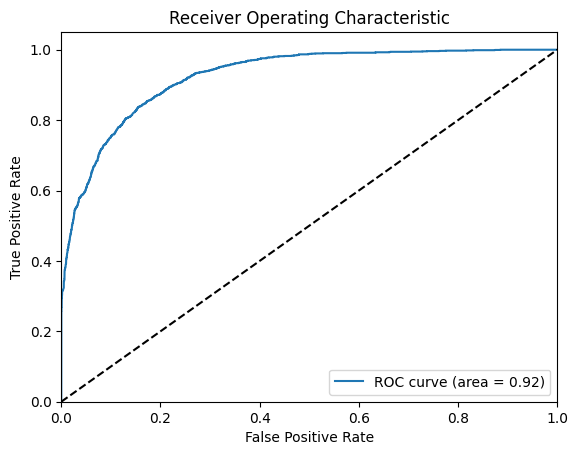

PR AUC: 0.8211110161663053


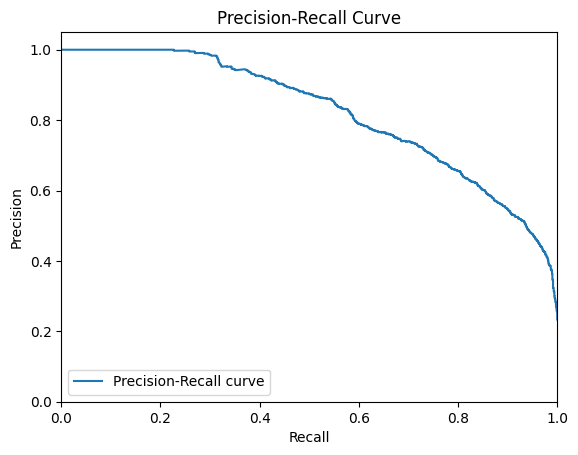

 85%|████████▍ | 11/13 [02:55<00:09,  4.90s/it]


Confusion Matrix:
 [[4684  304]
 [ 510 1010]]


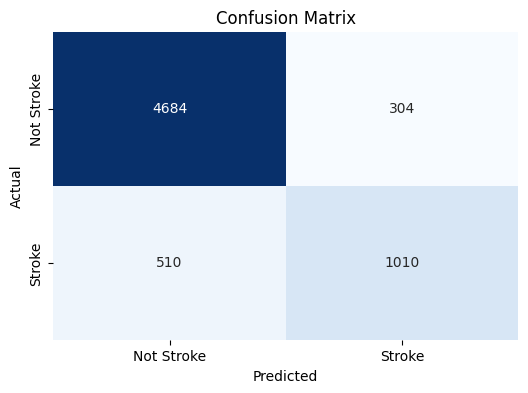


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.90      0.94      0.92      4988
      Stroke       0.77      0.66      0.71      1520

    accuracy                           0.87      6508
   macro avg       0.84      0.80      0.82      6508
weighted avg       0.87      0.87      0.87      6508

ROC-AUC: 0.9273646224623306


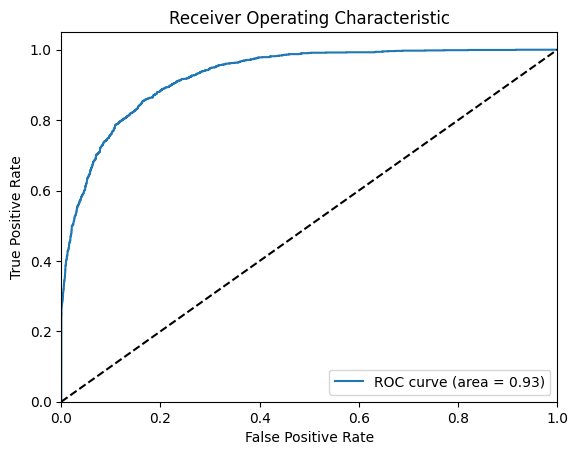

PR AUC: 0.8225038131171657


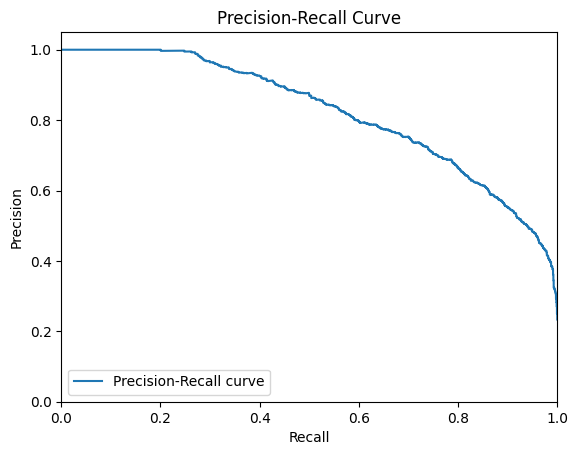

 92%|█████████▏| 12/13 [03:04<00:06,  6.01s/it]

[LightGBM] [Info] Number of positive: 6319, number of negative: 19710
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007491 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 433
[LightGBM] [Info] Number of data points in the train set: 26029, number of used features: 39
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.242768 -> initscore=-1.137565
[LightGBM] [Info] Start training from score -1.137565

Confusion Matrix:
 [[4673  315]
 [ 505 1015]]


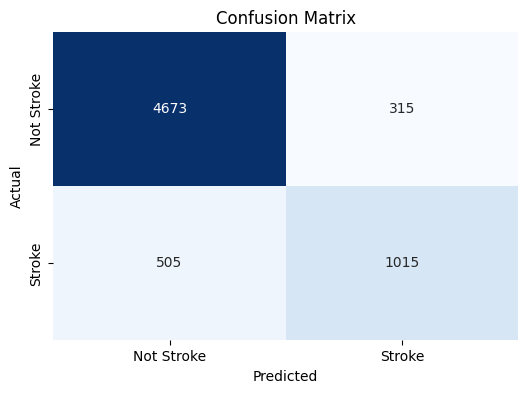


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.90      0.94      0.92      4988
      Stroke       0.76      0.67      0.71      1520

    accuracy                           0.87      6508
   macro avg       0.83      0.80      0.82      6508
weighted avg       0.87      0.87      0.87      6508

ROC-AUC: 0.925951494112185


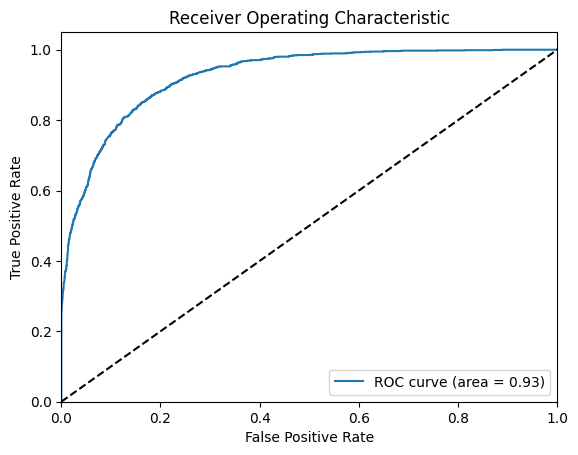

PR AUC: 0.8211659388210347


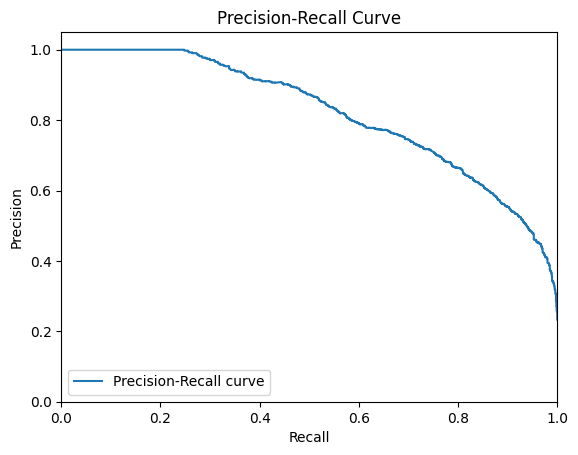

100%|██████████| 13/13 [03:05<00:00, 14.29s/it]


In [44]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:02:10] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4319  669]
 [ 306 1214]]


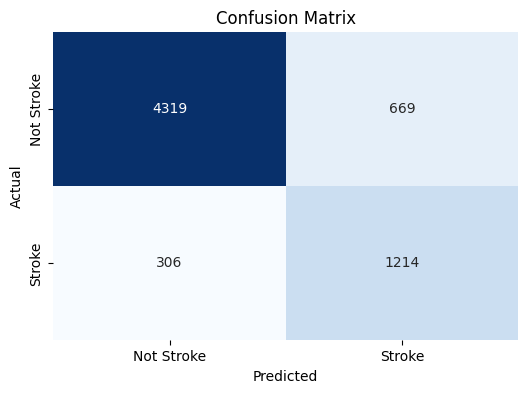


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.93      0.87      0.90      4988
      Stroke       0.64      0.80      0.71      1520

    accuracy                           0.85      6508
   macro avg       0.79      0.83      0.81      6508
weighted avg       0.87      0.85      0.86      6508

ROC-AUC: 0.9136763759338201


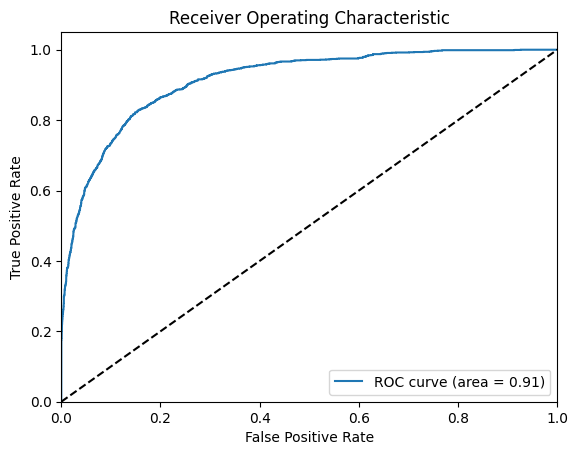

PR AUC: 0.7994515271001343


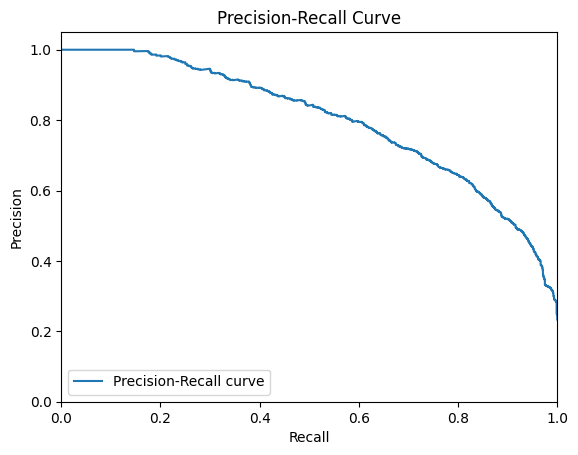

In [45]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:02:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4644  344]
 [ 536  984]]


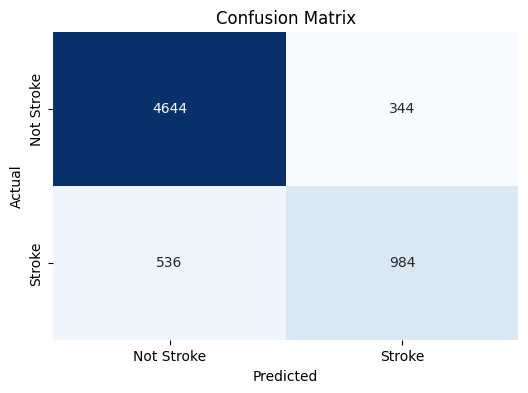


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.90      0.93      0.91      4988
      Stroke       0.74      0.65      0.69      1520

    accuracy                           0.86      6508
   macro avg       0.82      0.79      0.80      6508
weighted avg       0.86      0.86      0.86      6508

ROC-AUC: 0.9198498105980669


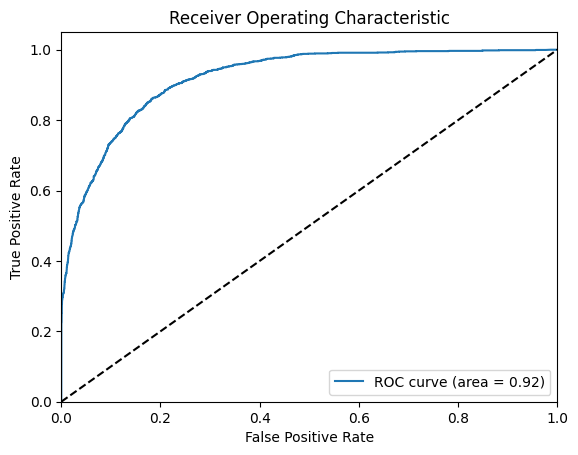

PR AUC: 0.8070007105642074


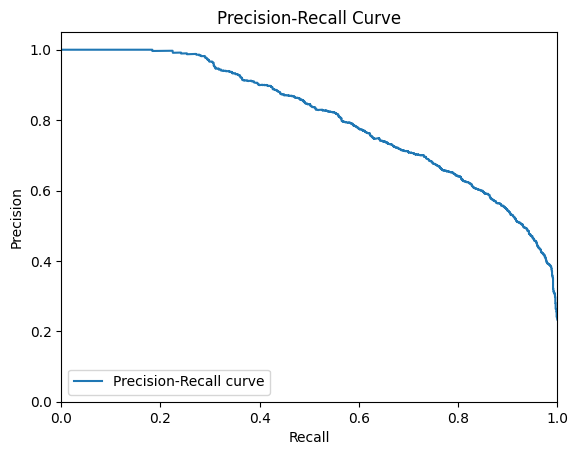

In [46]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [47]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [48]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Voting Classifier,0.912828,0.850184,0.773206,0.644716,0.906947,0.798684,0.834753,0.713488,0.910830,0.832281,0.913676,0.799452
CatBoost,0.893888,0.874923,0.832616,0.768645,0.704542,0.664474,0.763244,0.712773,0.829567,0.801764,0.927365,0.822504
LightGBM,0.887241,0.874001,0.816143,0.763158,0.691249,0.667763,0.748522,0.712281,0.820662,0.802306,0.925951,0.821166
Hist Gradient Boosting,0.885397,0.872772,0.809922,0.757440,0.689824,0.669737,0.745065,0.710894,0.818961,0.802190,0.925651,0.821395
XGBoost,0.898190,0.872465,0.837783,0.756696,0.720051,0.669079,0.774468,0.710196,0.837676,0.801761,0.924777,0.821111
Stacking Classifier,0.880595,0.864782,0.791750,0.740964,0.689508,0.647368,0.737100,0.691011,0.815682,0.789201,0.919850,0.807001
Gradient Boosting,0.869300,0.864014,0.805062,0.768840,0.609115,0.597368,0.693514,0.672344,0.780915,0.771319,0.920314,0.807003
Random Forest,0.978025,0.850184,0.966099,0.696184,0.942554,0.636184,0.954181,0.664833,0.965975,0.775791,0.898113,0.747251
SVC,0.862807,0.857406,0.780408,0.739095,0.605159,0.601974,0.681701,0.663524,0.775284,0.768609,0.892869,0.755602
KNN,0.880518,0.837738,0.772735,0.654255,0.719418,0.647368,0.745124,0.650794,0.825792,0.771559,0.864726,0.633457


<Axes: >

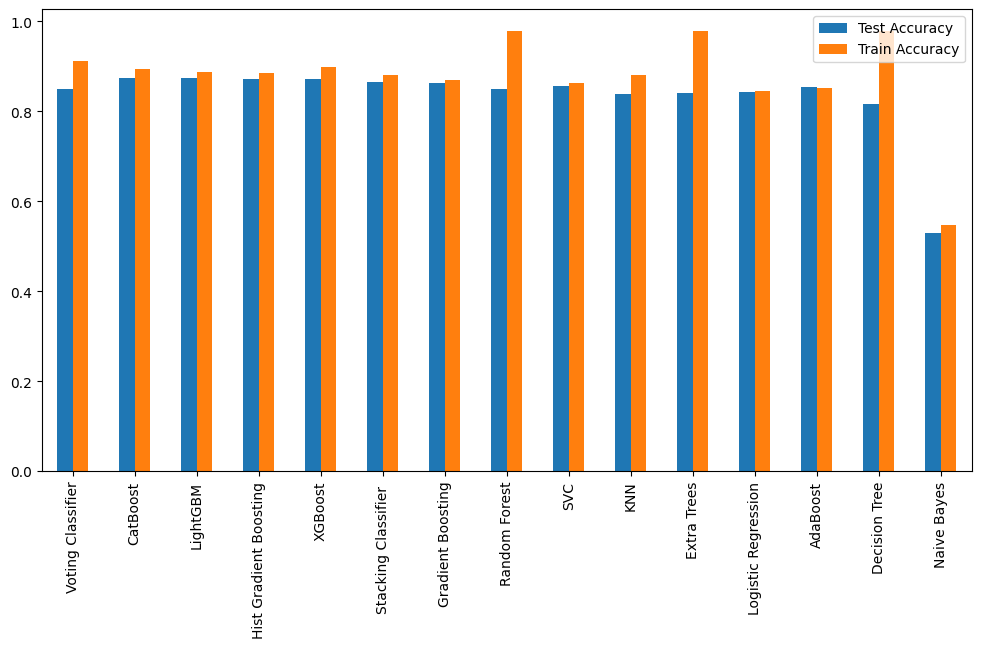

In [49]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

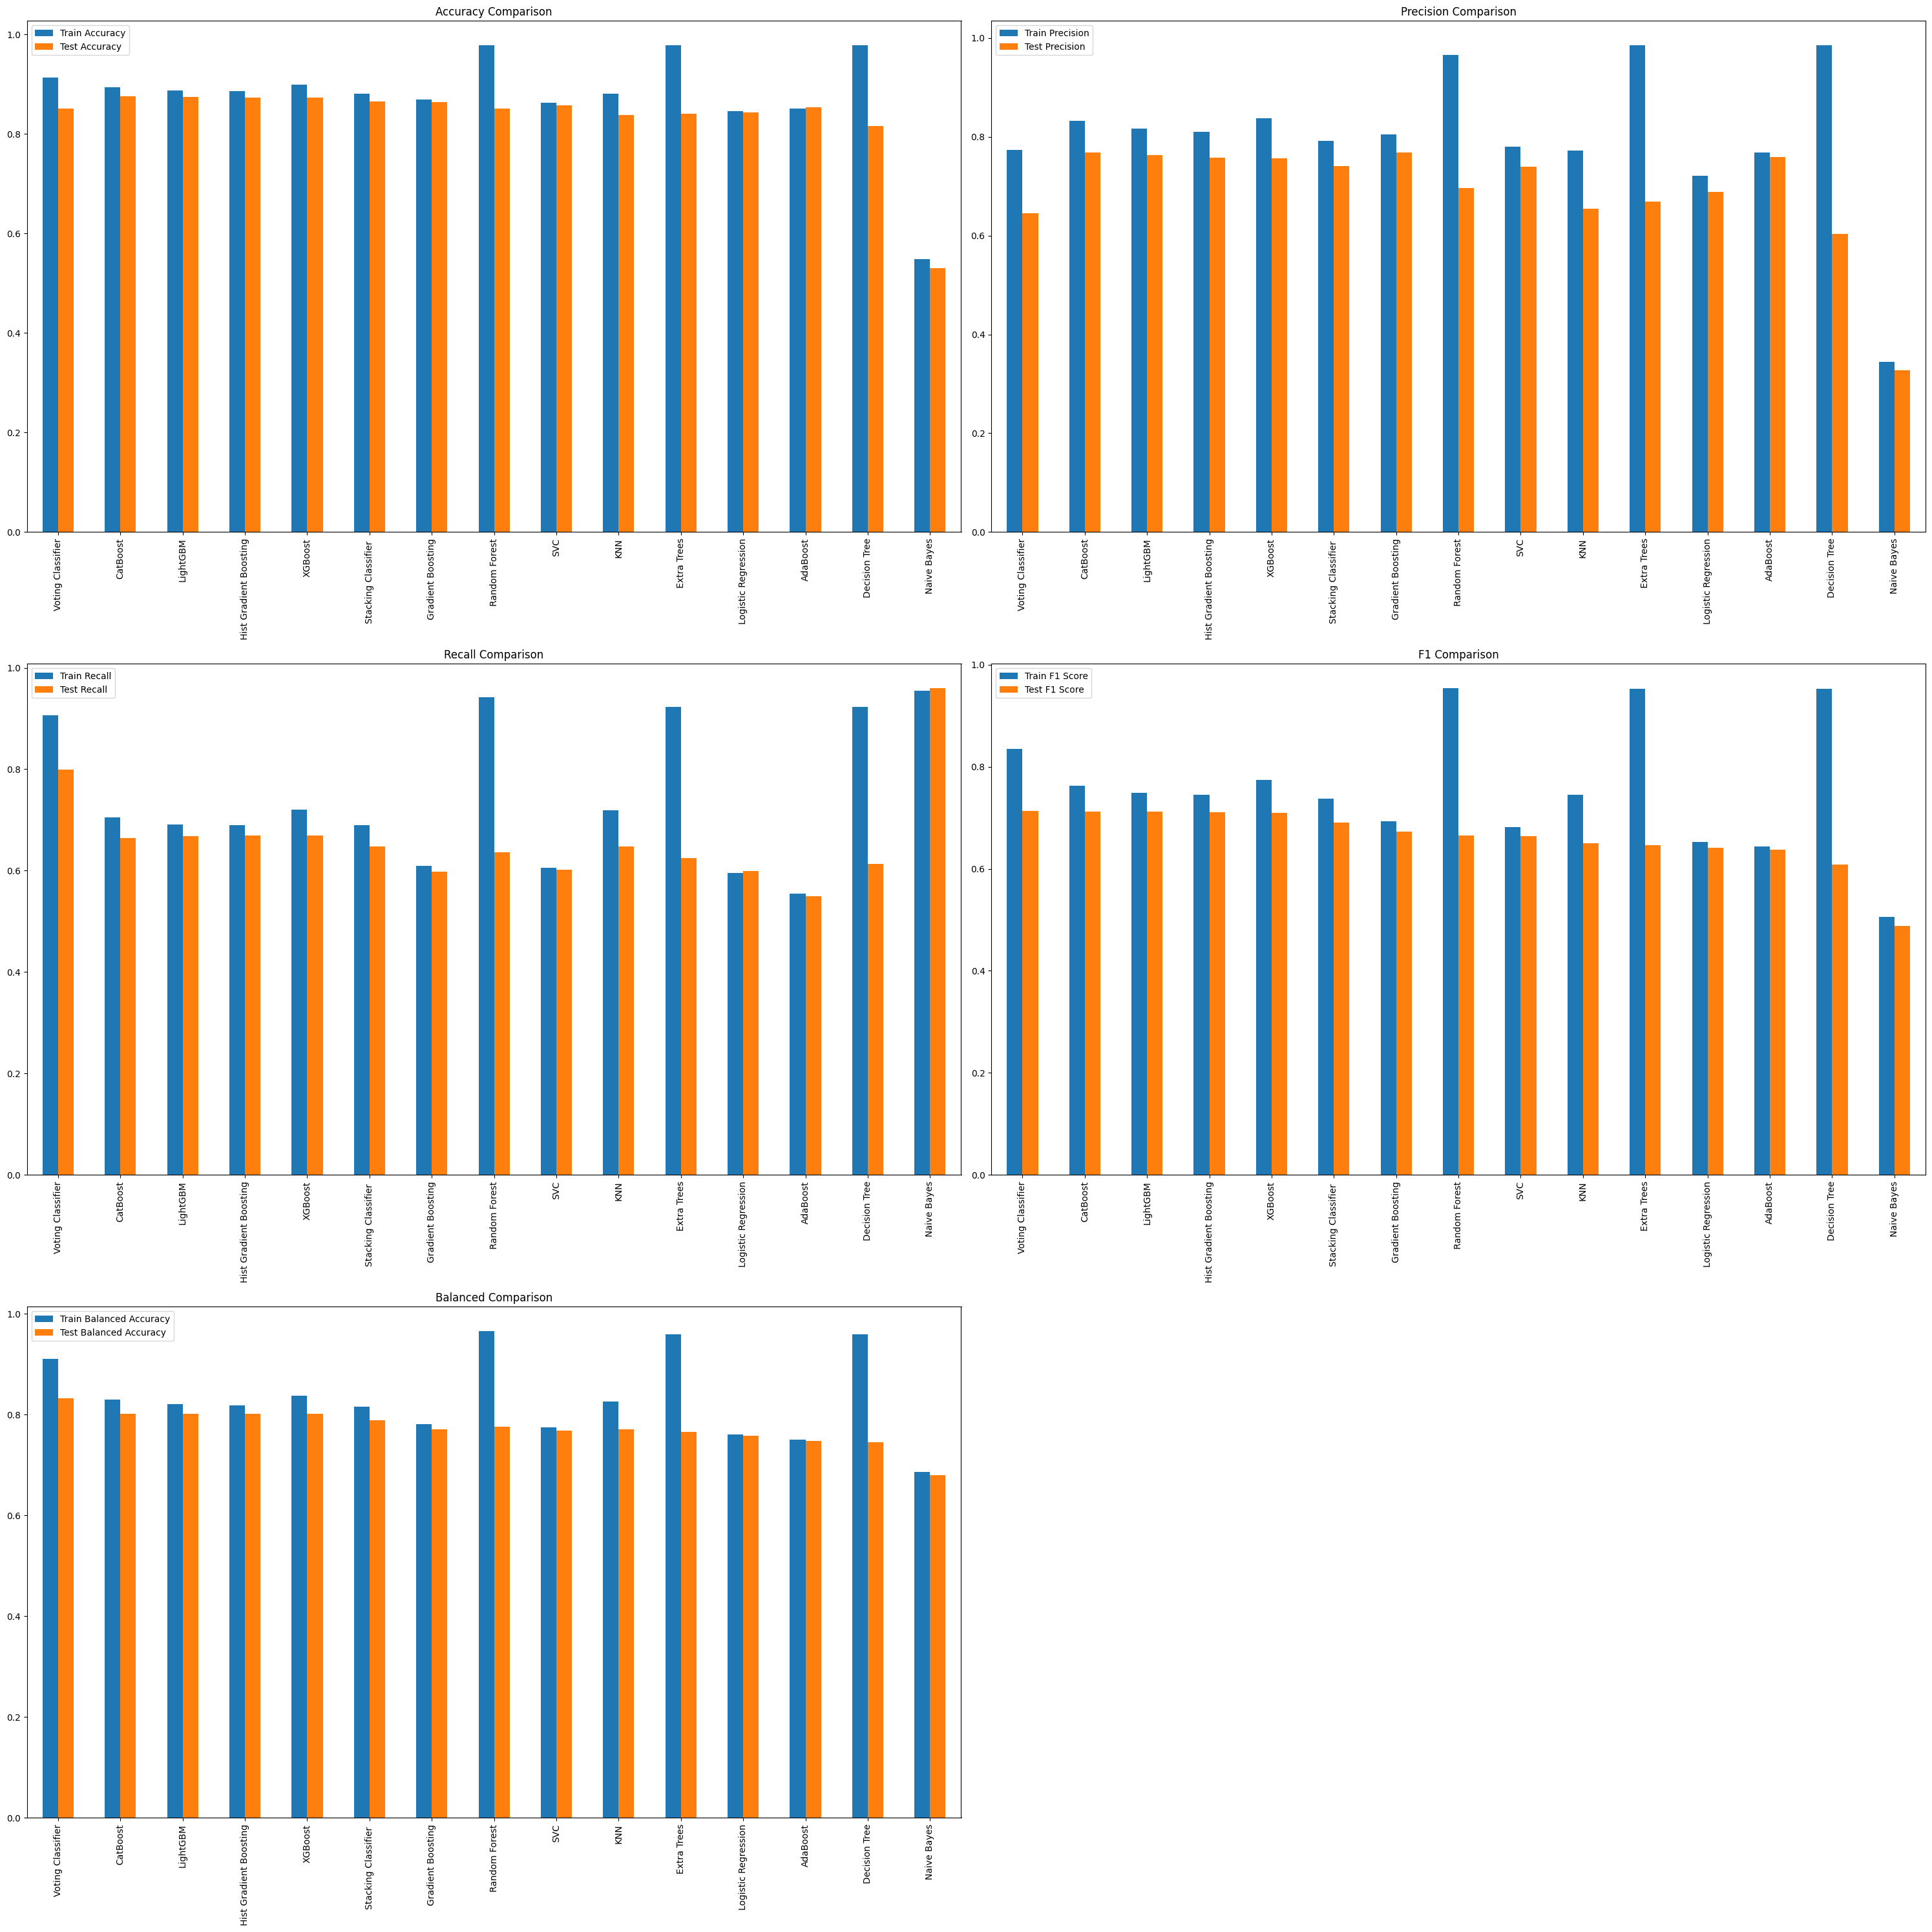

In [50]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()